# UCS420 — Cognitive Computing
## Lab Assignment 7: Sales Data Analysis with NumPy, Pandas, Matplotlib & Seaborn

| | |
|---|---|
| **Name** | Waris |
| **Roll No.** | 1024170155 |
| **Subgroup** | 3Q21 |
| **Programme** | B.Tech Computer Science & Engineering |
| **Institute** | Thapar Institute of Engineering and Technology, Patiala |

---


### Contents
1. **Q1 Part I** — Randomized sales data generation (NumPy)
2. **Q1 Part II** — Data manipulation and analysis (Pandas)
3. **Q1 Part III** — Visualizations (Matplotlib and Seaborn)
4. **Q2** — Absolute values, percentiles, mean / median / std on a 2-D array
5. **Q3** — Floor, ceiling, truncated and rounded values
6. **Q4** — Swapping two list elements with a temporary variable
7. **Q5** — Swapping two set elements via list conversion
8. **Conclusion**

Each step has a markdown explanation before the code, well-commented code, and an observation after the output. All plots are embedded below their cells and also saved as `.png` files.

In [23]:
# ---------------------------------------------------------------
# Setup: student details + all imports used in this notebook
# ---------------------------------------------------------------
ROLL_NO = 1024170155
NAME    = "Waris"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.precision", 2)          # tidy DataFrame output

assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"
PARITY = "even" if ROLL_NO % 2 == 0 else "odd"

print(f"Environment ready for {NAME} ({ROLL_NO})")
print(f"Roll number parity : {PARITY}")
print(f"numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Environment ready for Waris (1024170155)
Roll number parity : odd
numpy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2 | seaborn 0.13.2


---
# Q1. E-commerce Sales Analysis


In [24]:
# Step 1: seed NumPy's global random generator with my roll number
assert 0 <= ROLL_NO < 2**32, "Seed must fit in 32 bits"
np.random.seed(ROLL_NO)

print(f"Random seed initialised with roll number {ROLL_NO}")

Random seed initialised with roll number 1024170155


In [25]:
# Step 2: generate the sales array
CATEGORIES = ["Electronics", "Clothing", "Home & Kitchen", "Sports"]
MONTHS     = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Randomized range (seed-dependent) that always stays within 1000-5000
waris_low  = np.random.randint(1000, 2001)        # lower bound in [1000, 2000]
waris_high = np.random.randint(4000, 5001)        # upper bound in [4000, 5000]

# randint's upper limit is exclusive, so +1 makes waris_high reachable
waris_sales = np.random.randint(waris_low, waris_high + 1, size=(12, 4))

print(f"Randomized range for {NAME}: {waris_low} to {waris_high} units")
print(f"Array shape: {waris_sales.shape}   dtype: {waris_sales.dtype}")
print(f"Actual min = {waris_sales.min()}   Actual max = {waris_sales.max()}\n")
print(waris_sales)

Randomized range for Waris: 1566 to 4058 units
Array shape: (12, 4)   dtype: int64
Actual min = 1748   Actual max = 4046

[[2681 2029 1940 3059]
 [2738 2591 1945 2655]
 [2344 2636 2197 2872]
 [2086 1841 2677 2629]
 [1807 2591 2654 3253]
 [1789 2410 1770 3790]
 [4046 3359 2384 2268]
 [3305 1764 2164 2582]
 [2688 2164 2186 2107]
 [2251 1748 3697 2161]
 [3579 2935 2200 2369]
 [2428 3734 1994 3503]]



The question asks to convert the **cleaned** array, so before building the DataFrame I run a validation pass that a real sales feed would need: check for missing values, negative values and values outside the 1000–5000 business limit, then clip as a safety net and enforce an integer dtype (sales are whole units).

In [26]:
# Step 2b: validate and clean the raw array
checks = {
    "Missing (NaN) values"        : int(np.isnan(waris_sales.astype(float)).sum()),
    "Negative values"             : int((waris_sales < 0).sum()),
    "Values below 1000"           : int((waris_sales < 1000).sum()),
    "Values above 5000"           : int((waris_sales > 5000).sum()),
}
for check, n in checks.items():
    print(f"{check:<30}: {n}")

# Safety net: clip to the allowed range and force whole units
waris_sales_clean = np.clip(waris_sales, 1000, 5000).astype(int)

changed = int((waris_sales_clean != waris_sales).sum())
print(f"\nCells modified by cleaning    : {changed}")
print("Cleaned array is valid        :",
      bool(((waris_sales_clean >= 1000) & (waris_sales_clean <= 5000)).all()))

Missing (NaN) values          : 0
Negative values               : 0
Values below 1000             : 0
Values above 5000             : 0

Cells modified by cleaning    : 0
Cleaned array is valid        : True



Columns are the four categories and the index is the months Jan–Dec.

In [27]:
# Step 3: NumPy array -> labelled DataFrame
waris_sales_df = pd.DataFrame(waris_sales_clean, index=MONTHS, columns=CATEGORIES)
waris_sales_df.index.name = "Month"

print(f"{NAME}'s sales DataFrame — shape {waris_sales_df.shape}")
display(waris_sales_df)

Waris's sales DataFrame — shape (12, 4)


,Electronics,Clothing,Home & Kitchen,Sports
Month,,,,
Jan,2681,2029,1940,3059
Feb,2738,2591,1945,2655
Mar,2344,2636,2197,2872
Apr,2086,1841,2677,2629
May,1807,2591,2654,3253
Jun,1789,2410,1770,3790
Jul,4046,3359,2384,2268
Aug,3305,1764,2164,2582
Sep,2688,2164,2186,2107


**Observation (Part I):** The seed produced a randomized range of **1566 to 4058** units. All 48 values passed validation, so cleaning changed nothing, but the check makes the pipeline safe if the data source changes. The DataFrame is now labelled by month and category, which makes the analysis below readable.

---
## Part II — Data Manipulation and Analysis (Pandas)


`head()` shows the first five months; `describe()` gives count, mean, standard deviation, min, quartiles and max for each category.

In [28]:
# Step 1a: first 5 rows
print("First 5 rows:")
display(waris_sales_df.head())

First 5 rows:


,Electronics,Clothing,Home & Kitchen,Sports
Month,,,,
Jan,2681,2029,1940,3059
Feb,2738,2591,1945,2655
Mar,2344,2636,2197,2872
Apr,2086,1841,2677,2629
May,1807,2591,2654,3253


In [29]:
# Step 1b: summary statistics (transposed so each category is one row)
print("Summary statistics per category:")
display(waris_sales_df.describe().T)

# Coefficient of variation = std / mean -> relative volatility of each category
cv = (waris_sales_df.std() / waris_sales_df.mean() * 100).round(2)
print("Coefficient of variation (%) — higher means more volatile sales:")
print(cv.sort_values(ascending=False).to_string())

Summary statistics per category:


,count,mean,std,min,25%,50%,75%,max
Electronics,12.0,2645.17,695.63,1789.0,2209.75,2554.5,2879.75,4046.0
Clothing,12.0,2483.50,630.01,1748.0,1982.00,2500.5,2710.75,3734.0
Home & Kitchen,12.0,2317.33,513.88,1770.0,1981.75,2191.5,2451.50,3697.0
Sports,12.0,2770.67,539.07,2107.0,2343.75,2642.0,3107.50,3790.0


Coefficient of variation (%) — higher means more volatile sales:
Electronics       26.30
Clothing          25.37
Home & Kitchen    22.18
Sports            19.46



* Per category: sum down the rows (`axis=0`).
* Per month: sum across the columns (`axis=1`).

In [30]:
# Step 2: totals
category_totals = waris_sales_df.sum(axis=0).sort_values(ascending=False)
monthly_totals  = waris_sales_df.sum(axis=1)

cat_table = pd.DataFrame({"Total Sales": category_totals,
                          "Share (%)": (category_totals / category_totals.sum() * 100).round(2)})
print("Total sales per category (sorted):")
display(cat_table)

print("Total sales per month:")
display(monthly_totals.to_frame("Total Sales").T)

print(f"Grand total for the year : {category_totals.sum():,} units")
print(f"Best category            : {category_totals.idxmax()} ({category_totals.max():,})")
print(f"Weakest category         : {category_totals.idxmin()} ({category_totals.min():,})")
print(f"Best month               : {monthly_totals.idxmax()} ({monthly_totals.max():,})")
print(f"Weakest month            : {monthly_totals.idxmin()} ({monthly_totals.min():,})")

Total sales per category (sorted):


,Total Sales,Share (%)
Sports,33248,27.12
Electronics,31742,25.89
Clothing,29802,24.31
Home & Kitchen,27808,22.68


Total sales per month:


Month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Total Sales,9709,9929,10049,9233,10305,9759,12057,9815,9145,9857,11083,11659


Grand total for the year : 122,600 units
Best category            : Sports (33,248)
Weakest category         : Home & Kitchen (27,808)
Best month               : Jul (12,057)
Weakest month            : Sep (9,145)



`pct_change()` gives the month-over-month growth `(current − previous) / previous × 100` for each category. Its mean is the **average growth rate** asked for in the question. Jan has no previous month, so its growth is `NaN` and is skipped by `mean()`.

To go a step further, I also report:
* the **average absolute change** in units (`diff().mean()`), and
* the **compound monthly growth rate** `(Dec / Jan)^(1/11) − 1`, which is the steady rate that turns January's sales into December's.

The comparison matters: an arithmetic mean of percentages can be misleading when sales swing up and down a lot.

In [31]:
# Step 3: month-over-month growth per category
mom_growth = waris_sales_df.pct_change() * 100
print("Month-over-month growth (%) per category:")
display(mom_growth.round(2))

n_steps = len(waris_sales_df) - 1                               # 11 transitions
growth_summary = pd.DataFrame({
    "Avg MoM growth (%)"        : mom_growth.mean(),
    "Avg change (units)"        : waris_sales_df.diff().mean(),
    "Compound monthly growth (%)": ((waris_sales_df.iloc[-1] / waris_sales_df.iloc[0]) ** (1 / n_steps) - 1) * 100,
    "Jan -> Dec change (units)" : waris_sales_df.iloc[-1] - waris_sales_df.iloc[0],
}).round(2)
print("Average growth between consecutive months:")
display(growth_summary)

Month-over-month growth (%) per category:


,Electronics,Clothing,Home & Kitchen,Sports
Month,,,,
Jan,NaN,NaN,NaN,NaN
Feb,2.13,27.70,0.26,-13.21
Mar,-14.39,1.74,12.96,8.17
Apr,-11.01,-30.16,21.85,-8.46
May,-13.37,40.74,-0.86,23.74
Jun,-1.00,-6.99,-33.31,16.51
Jul,126.16,39.38,34.69,-40.16
Aug,-18.31,-47.48,-9.23,13.84
Sep,-18.67,22.68,1.02,-18.40


Average growth between consecutive months:


,Avg MoM growth (%),Avg change (units),Compound monthly growth (%),Jan -> Dec change (units)
Electronics,5.65,-23.00,-0.90,-253
Clothing,11.23,155.00,5.70,1705
Home & Kitchen,4.24,4.91,0.25,54
Sports,3.83,40.36,1.24,444


**Observation (Step 3):** Every category shows a *positive* average month-over-month growth, but the compound rate tells a different story for **Electronics**: its average MoM growth is about **+5.65 %**, yet December (2428) is actually *lower* than January (2681), giving a compound rate of about **−0.90 %** per month. This happens because large rebounds (e.g. Jun → Jul: +126 %) inflate the arithmetic mean far more than equal-sized drops deflate it. **Clothing** is the genuine growth story, rising from 2029 to 3734 units (≈ +5.7 % compounded per month).


* **Total Sales** = sum of the four categories in that month.
* **Growth Rate** = percentage change in Total Sales from the previous month (in %). Jan is `NaN` because there is no December of the previous year to compare with.

In [32]:
# Step 4: new columns
waris_sales_df["Total Sales"] = waris_sales_df[CATEGORIES].sum(axis=1)
waris_sales_df["Growth Rate"] = waris_sales_df["Total Sales"].pct_change() * 100   # in %

print("DataFrame with Total Sales and Growth Rate (%):")
display(waris_sales_df.round(2))

best_g, worst_g = waris_sales_df["Growth Rate"].idxmax(), waris_sales_df["Growth Rate"].idxmin()
print(f"Strongest growth : {best_g} ({waris_sales_df.loc[best_g, 'Growth Rate']:+.2f} %)")
print(f"Sharpest decline : {worst_g} ({waris_sales_df.loc[worst_g, 'Growth Rate']:+.2f} %)")

DataFrame with Total Sales and Growth Rate (%):


,Electronics,Clothing,Home & Kitchen,Sports,Total Sales,Growth Rate
Month,,,,,,
Jan,2681,2029,1940,3059,9709,NaN
Feb,2738,2591,1945,2655,9929,2.27
Mar,2344,2636,2197,2872,10049,1.21
Apr,2086,1841,2677,2629,9233,-8.12
May,1807,2591,2654,3253,10305,11.61
Jun,1789,2410,1770,3790,9759,-5.30
Jul,4046,3359,2384,2268,12057,23.55
Aug,3305,1764,2164,2582,9815,-18.60
Sep,2688,2164,2186,2107,9145,-6.83


Strongest growth : Jul (+23.55 %)
Sharpest decline : Aug (-18.60 %)



Rule from the question:
* roll number **even** → 10 % discount on **Electronics**
* roll number **odd** → 15 % discount on **Clothing**

The rule is chosen in code from `ROLL_NO % 2`, not hard-coded. My roll number **1024170155 is odd**, so **Clothing gets 15 % off**. The discount is applied to a copy so the original data stays available for comparison, and `Total Sales` and `Growth Rate` are recalculated so the derived columns stay consistent with the discounted values.

In [33]:
# Step 5: discount decided by roll-number parity
if ROLL_NO % 2 == 0:
    DISCOUNT_CATEGORY, DISCOUNT_RATE = "Electronics", 0.10
else:
    DISCOUNT_CATEGORY, DISCOUNT_RATE = "Clothing", 0.15

print(f"Roll number {ROLL_NO} is {PARITY} -> {DISCOUNT_RATE:.0%} discount on {DISCOUNT_CATEGORY}\n")

waris_discounted_df = waris_sales_df.copy()
waris_discounted_df[DISCOUNT_CATEGORY] = (waris_discounted_df[DISCOUNT_CATEGORY] * (1 - DISCOUNT_RATE)).round(2)

# keep derived columns consistent with the discounted data
waris_discounted_df["Total Sales"] = waris_discounted_df[CATEGORIES].sum(axis=1)
waris_discounted_df["Growth Rate"] = waris_discounted_df["Total Sales"].pct_change() * 100

comparison = pd.DataFrame({
    f"{DISCOUNT_CATEGORY} (before)": waris_sales_df[DISCOUNT_CATEGORY],
    f"{DISCOUNT_CATEGORY} (after)" : waris_discounted_df[DISCOUNT_CATEGORY],
    "Reduction"                   : waris_sales_df[DISCOUNT_CATEGORY] - waris_discounted_df[DISCOUNT_CATEGORY],
})
print(f"{DISCOUNT_CATEGORY} before vs after discount:")
display(comparison.round(2))

print("Final DataFrame after discount:")
display(waris_discounted_df.round(2))

before, after = waris_sales_df[DISCOUNT_CATEGORY].sum(), waris_discounted_df[DISCOUNT_CATEGORY].sum()
print(f"{DISCOUNT_CATEGORY} yearly total : {before:,.2f} -> {after:,.2f}  (−{before - after:,.2f})")
print(f"Overall yearly total   : {waris_sales_df['Total Sales'].sum():,.2f} -> {waris_discounted_df['Total Sales'].sum():,.2f}")

Roll number 1024170155 is odd -> 15% discount on Clothing

Clothing before vs after discount:


,Clothing (before),Clothing (after),Reduction
Month,,,
Jan,2029,1724.65,304.35
Feb,2591,2202.35,388.65
Mar,2636,2240.60,395.40
Apr,1841,1564.85,276.15
May,2591,2202.35,388.65
Jun,2410,2048.50,361.50
Jul,3359,2855.15,503.85
Aug,1764,1499.40,264.60
Sep,2164,1839.40,324.60


Final DataFrame after discount:


,Electronics,Clothing,Home & Kitchen,Sports,Total Sales,Growth Rate
Month,,,,,,
Jan,2681,1724.65,1940,3059,9404.65,NaN
Feb,2738,2202.35,1945,2655,9540.35,1.44
Mar,2344,2240.60,2197,2872,9653.60,1.19
Apr,2086,1564.85,2677,2629,8956.85,-7.22
May,1807,2202.35,2654,3253,9916.35,10.71
Jun,1789,2048.50,1770,3790,9397.50,-5.23
Jul,4046,2855.15,2384,2268,11553.15,22.94
Aug,3305,1499.40,2164,2582,9550.40,-17.34
Sep,2688,1839.40,2186,2107,8820.40,-7.64


Clothing yearly total : 29,802.00 -> 25,331.70  (−4,470.30)
Overall yearly total   : 122,600.00 -> 118,129.70


**Observation (Part II):** Sports is the top category (33,248 units, 27.1 % share) and July is the best month (12,057 units, +23.55 % over June), immediately followed by the sharpest drop in August (−18.60 %). Sales recover strongly in Nov–Dec, which fits a festive-season pattern. After the 15 % Clothing discount, Clothing's yearly total falls from 29,802 to 25,331.70, so it drops from 3rd place to last, below Home & Kitchen (27,808). The discount scales every Clothing month by the same factor, so Clothing's *own* growth pattern is unchanged, but the overall monthly growth rates shift slightly because Clothing now weighs less in the total.

---
## Part III — Visualizations (Matplotlib and Seaborn)

All plots use the **final (discounted)** DataFrame from Part II, since each part builds on the previous one. Each figure is also saved as a `.png` file for the screenshot requirement.

### Plot 1: Monthly sales trend per category (line plot)
The dotted grey line shows Clothing *before* the discount, so the effect of Step 5 is visible.

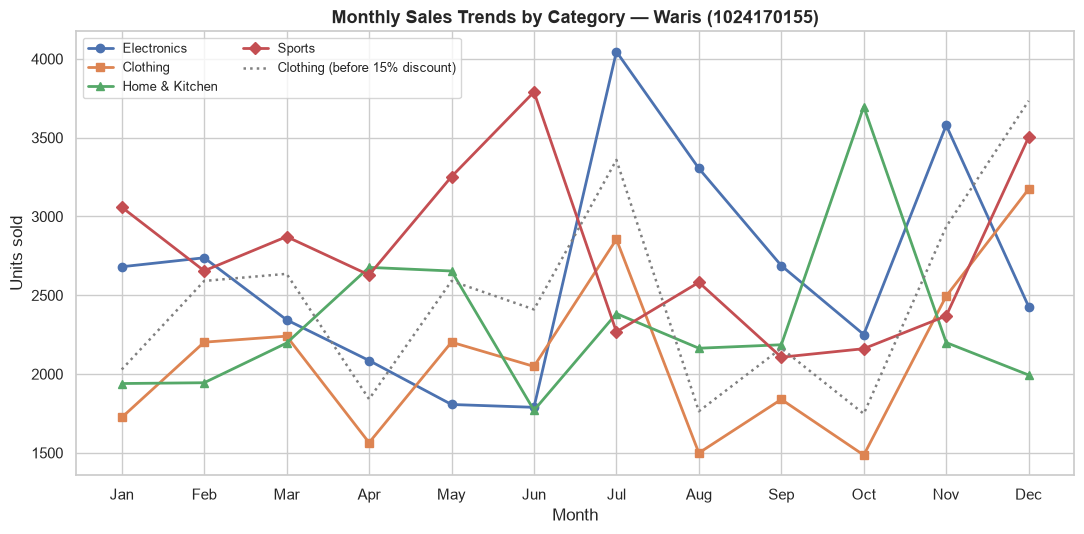

In [34]:
# Plot 1: line plot of monthly trends
fig, ax = plt.subplots(figsize=(11, 5.5))
markers = ["o", "s", "^", "D"]
for cat, mk in zip(CATEGORIES, markers):
    ax.plot(waris_discounted_df.index, waris_discounted_df[cat], marker=mk, linewidth=2, label=cat)

ax.plot(waris_sales_df.index, waris_sales_df[DISCOUNT_CATEGORY], linestyle=":", color="grey",
        linewidth=1.8, label=f"{DISCOUNT_CATEGORY} (before {DISCOUNT_RATE:.0%} discount)")

ax.set_title(f"Monthly Sales Trends by Category — {NAME} ({ROLL_NO})", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Units sold")
ax.legend(loc="upper left", ncol=2, fontsize=9)
fig.tight_layout()
plt.savefig("Waris_plot1_monthly_trends.png", dpi=120, bbox_inches="tight")
plt.show()

**Observation:** Electronics is the most volatile line, with a sharp spike in July (4046) right after its yearly low in June (1789). Home & Kitchen stays in a narrow band except for one October peak (3697). Sports peaks in June (3790), while Clothing climbs to its high in December. No single category leads every month, so the categories peak at different times of the year.

### Plot 2: Sales distribution per category (box plot)
A box plot shows the median (centre line), the inter-quartile range (box), the whiskers (1.5 × IQR) and any outliers (points). I reshape the DataFrame to long format with `melt()` because Seaborn expects one row per observation.

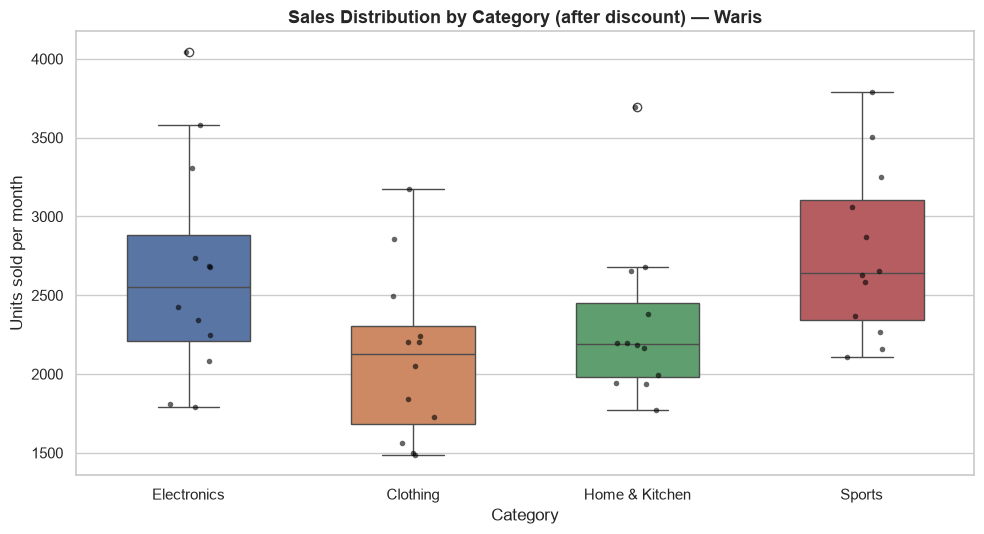

,Q1,Median,Q3,IQR
Electronics,2209.75,2554.50,2879.75,670.00
Clothing,1684.70,2125.43,2304.14,619.44
Home & Kitchen,1981.75,2191.50,2451.50,469.75
Sports,2343.75,2642.00,3107.50,763.75


In [35]:
# Plot 2: box plot of the distribution for each category
long_df = (waris_discounted_df[CATEGORIES]
           .reset_index()
           .melt(id_vars="Month", var_name="Category", value_name="Units"))

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=long_df, x="Category", y="Units", hue="Category", width=0.55, ax=ax, legend=False)
sns.stripplot(data=long_df, x="Category", y="Units", color="black", size=4, alpha=0.6, ax=ax)

ax.set_title(f"Sales Distribution by Category (after discount) — {NAME}", fontsize=13, fontweight="bold")
ax.set_xlabel("Category")
ax.set_ylabel("Units sold per month")
fig.tight_layout()
plt.savefig("Waris_plot2_boxplot.png", dpi=120, bbox_inches="tight")
plt.show()

# numbers behind the boxes
q = waris_discounted_df[CATEGORIES].quantile([0.25, 0.5, 0.75]).T
q.columns = ["Q1", "Median", "Q3"]
q["IQR"] = q["Q3"] - q["Q1"]
display(q.round(2))

**Observation:** Sports has the highest median (2642) and the widest box (IQR ≈ 764), while Electronics has the widest overall range (1789 to 4046, with the July spike flagged as an outlier) and the highest standard deviation, confirming the coefficient of variation in Part II. Home & Kitchen has the narrowest box, so it is the most predictable category for inventory planning, and its October peak shows up as an outlier point above the whisker. The discounted Clothing box sits lowest overall.

### Additional insights (beyond the required plots)
Two extra visuals that a business team would ask for next:
* **Plot 3:** Total monthly sales (bars) with the month-over-month Growth Rate (line) on a second axis.
* **Plot 4:** A heatmap of units per category and month, to spot hot and cold cells at a glance.

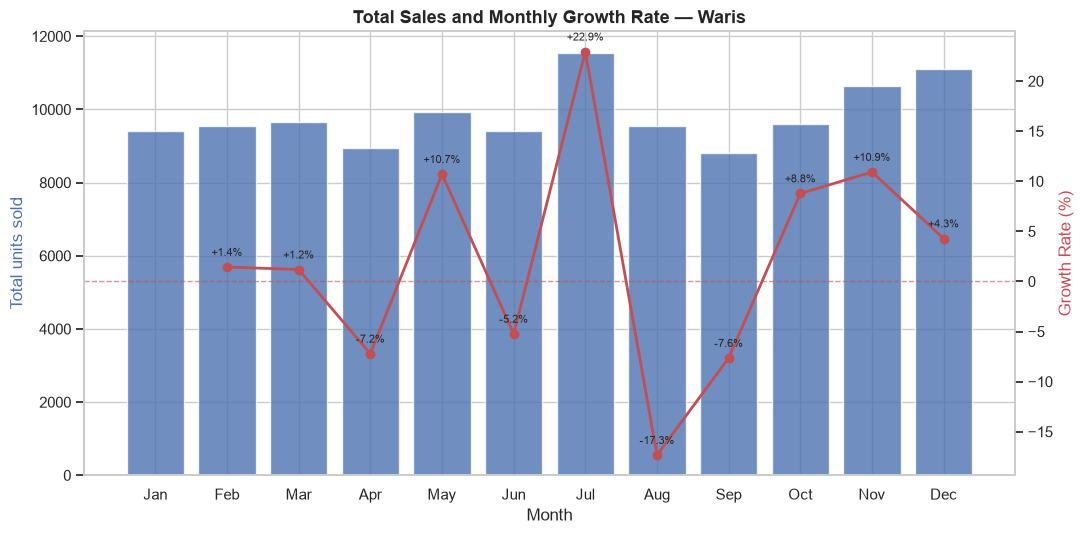

In [36]:
# Plot 3: Total Sales bars + Growth Rate line (twin axes)
fig, ax1 = plt.subplots(figsize=(11, 5.5))
ax1.bar(waris_discounted_df.index, waris_discounted_df["Total Sales"], color="#4C72B0", alpha=0.8, label="Total Sales")
ax1.set_ylabel("Total units sold", color="#4C72B0")
ax1.set_xlabel("Month")

ax2 = ax1.twinx()
ax2.plot(waris_discounted_df.index, waris_discounted_df["Growth Rate"], color="#C44E52",
         marker="o", linewidth=2, label="Growth Rate (%)")
ax2.axhline(0, color="#C44E52", linestyle="--", linewidth=1, alpha=0.6)
ax2.set_ylabel("Growth Rate (%)", color="#C44E52")
ax2.grid(False)

for m, g in waris_discounted_df["Growth Rate"].dropna().items():
    ax2.annotate(f"{g:+.1f}%", (m, g), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)

ax1.set_title(f"Total Sales and Monthly Growth Rate — {NAME}", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.savefig("Waris_plot3_total_and_growth.png", dpi=120, bbox_inches="tight")
plt.show()

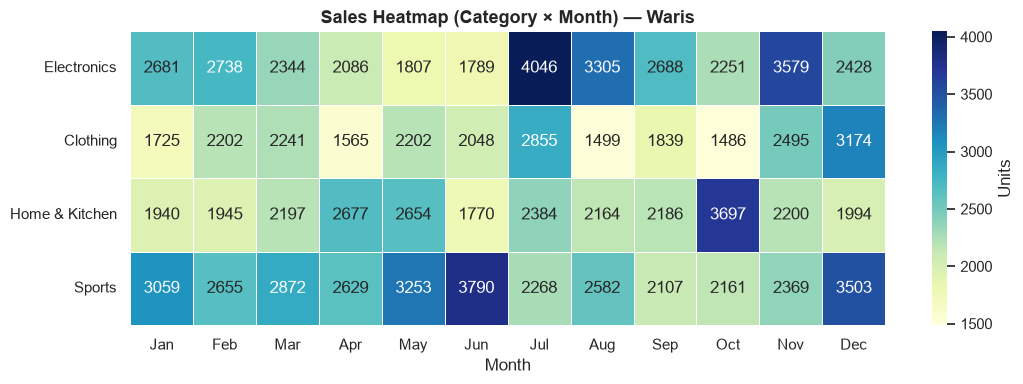

In [37]:
# Plot 4: heatmap of units per category and month
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(waris_discounted_df[CATEGORIES].T, annot=True, fmt=".0f", cmap="YlGnBu",
            linewidths=0.5, cbar_kws={"label": "Units"}, ax=ax)
ax.set_title(f"Sales Heatmap (Category × Month) — {NAME}", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("")
fig.tight_layout()
plt.savefig("Waris_plot4_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

**Observation (Part III):** The growth line alternates between gains and losses through most of the year, and the three biggest totals fall in July, November and December. For the business this suggests (1) stocking up before July and the Nov–Dec season, (2) investigating the August dip that follows the July spike, and (3) treating Home & Kitchen as the stable baseline category while monitoring Electronics closely because of its volatility.

---
# Q2. NumPy statistics on `array = np.array([[1, -2, 3], [-4, 5, -6]])`

Throughout this question:
* **flattened** = all 6 values treated as one list (`axis=None`)
* **each column** = statistic down the rows (`axis=0`), giving 3 results
* **each row** = statistic across the columns (`axis=1`), giving 2 results

In [38]:
waris_array = np.array([[1, -2, 3],
                        [-4, 5, -6]])
print("Array:\n", waris_array)
print("Shape:", waris_array.shape)
print("Flattened:", waris_array.flatten())

Array:
 [[ 1 -2  3]
 [-4  5 -6]]
Shape: (2, 3)
Flattened: [ 1 -2  3 -4  5 -6]


### (i) Element-wise absolute value
`np.abs()` replaces each element with its distance from zero.

In [39]:
abs_array = np.abs(waris_array)
print("Element-wise absolute value:\n", abs_array)

Element-wise absolute value:
 [[1 2 3]
 [4 5 6]]


### (ii) 25th, 50th and 75th percentiles
`np.percentile()` uses linear interpolation by default. For the flattened array the sorted values are `[-6, -4, -2, 1, 3, 5]`.

In [40]:
P = [25, 50, 75]
labels = [f"P{p}" for p in P]

pct_flat = np.percentile(waris_array, P)              # flattened
pct_col  = np.percentile(waris_array, P, axis=0)      # each column -> shape (3, 3)
pct_row  = np.percentile(waris_array, P, axis=1)      # each row    -> shape (3, 2)

print("Flattened array:")
display(pd.DataFrame([pct_flat], columns=labels, index=["Flattened"]))

print("Each column:")
display(pd.DataFrame(pct_col.T, columns=labels, index=["Column 0", "Column 1", "Column 2"]))

print("Each row:")
display(pd.DataFrame(pct_row.T, columns=labels, index=["Row 0", "Row 1"]))

Flattened array:


,P25,P50,P75
Flattened,-3.5,-0.5,2.5


Each column:


,P25,P50,P75
Column 0,-2.75,-1.5,-0.25
Column 1,-0.25,1.5,3.25
Column 2,-3.75,-1.5,0.75


Each row:


,P25,P50,P75
Row 0,-0.5,1.0,2.0
Row 1,-5.0,-4.0,0.5


### (iii) Mean, median and standard deviation
`np.std()` uses the **population** standard deviation by default (`ddof=0`, dividing by *n*), which is what the question expects.

In [41]:
stats = {}
stats["Flattened"] = [np.mean(waris_array), np.median(waris_array), np.std(waris_array)]
for j in range(waris_array.shape[1]):
    col = waris_array[:, j]
    stats[f"Column {j}"] = [np.mean(col), np.median(col), np.std(col)]
for i in range(waris_array.shape[0]):
    row = waris_array[i, :]
    stats[f"Row {i}"] = [np.mean(row), np.median(row), np.std(row)]

stats_df = pd.DataFrame(stats, index=["Mean", "Median", "Std Dev"]).T
display(stats_df.round(4))

# cross-check with the vectorised axis versions
print("Column means (axis=0):", np.mean(waris_array, axis=0))
print("Row means    (axis=1):", np.mean(waris_array, axis=1))
print("Column std   (axis=0):", np.std(waris_array, axis=0))
print("Row std      (axis=1):", np.round(np.std(waris_array, axis=1), 4))

,Mean,Median,Std Dev
Flattened,-0.50,-0.5,3.86
Column 0,-1.50,-1.5,2.50
Column 1,1.50,1.5,3.50
Column 2,-1.50,-1.5,4.50
Row 0,0.67,1.0,2.05
Row 1,-1.67,-4.0,4.78


Column means (axis=0): [-1.5  1.5 -1.5]
Row means    (axis=1): [ 0.66666667 -1.66666667]
Column std   (axis=0): [2.5 3.5 4.5]
Row std      (axis=1): [2.0548 4.7842]


**Observation (Q2):** The flattened mean is −0.5 while the median is also −0.5 (the average of −2 and 1). Each column has a median equal to its mean because a column has only two values. The rows behave very differently: row 0 has mean 0.67 and row 1 has mean −1.67, and the large standard deviations (≈ 3.86 for the whole array) reflect the alternating signs. Row 1 also shows how a single extreme value pulls the mean (−1.67) away from the median (−4).

---
# Q3. Floor, ceiling, truncated and rounded values of `a = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0])`

| Function | Rule |
|---|---|
| `np.floor` | largest integer **≤ x** (rounds toward −∞) |
| `np.ceil` | smallest integer **≥ x** (rounds toward +∞) |
| `np.trunc` | drops the decimal part (rounds toward 0) |
| `np.round` | nearest integer; exact halves go to the **nearest even** number |

In [42]:
a = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0])

waris_rounding = pd.DataFrame({
    "Value"  : a,
    "floor"  : np.floor(a),
    "ceil"   : np.ceil(a),
    "trunc"  : np.trunc(a),
    "round"  : np.round(a),
})
display(waris_rounding)

print("Floor    :", np.floor(a))
print("Ceiling  :", np.ceil(a))
print("Truncated:", np.trunc(a))
print("Rounded  :", np.round(a))

,Value,floor,ceil,trunc,round
0,-1.8,-2.0,-1.0,-1.0,-2.0
1,-1.6,-2.0,-1.0,-1.0,-2.0
2,-0.5,-1.0,-0.0,-0.0,-0.0
3,0.5,0.0,1.0,0.0,0.0
4,1.6,1.0,2.0,1.0,2.0
5,1.8,1.0,2.0,1.0,2.0
6,3.0,3.0,3.0,3.0,3.0


Floor    : [-2. -2. -1.  0.  1.  1.  3.]
Ceiling  : [-1. -1. -0.  1.  2.  2.  3.]
Truncated: [-1. -1. -0.  0.  1.  1.  3.]
Rounded  : [-2. -2. -0.  0.  2.  2.  3.]


**Observation (Q3):**
* For **negative** numbers, `floor` and `trunc` differ: `floor(-1.8) = -2` but `trunc(-1.8) = -1`. For positive numbers they agree.
* `np.round(-0.5)` and `np.round(0.5)` both give **0** (shown as `-0.` and `0.`), not ±1. NumPy uses *round half to even* (banker's rounding), which avoids a systematic upward bias when many values are rounded.
* `3.0` is already an integer, so all four functions return 3.

---
# Q4. Swap two elements in a list using a temporary variable

**Logic:** store the first element in `temp`, copy the second element into the first position, then copy `temp` into the second position. The function validates the indices and also accepts negative indices, just like normal Python indexing.

In [43]:
def swap_with_temp(lst, i, j):
    """Swap lst[i] and lst[j] in place using a temporary variable."""
    n = len(lst)
    if not (-n <= i < n and -n <= j < n):
        raise IndexError(f"Indices ({i}, {j}) out of range for a list of length {n}")
    temp   = lst[i]      # 1. save the first element
    lst[i] = lst[j]      # 2. overwrite it with the second
    lst[j] = temp        # 3. put the saved value in the second position
    return lst

# Example 1: the letters of my name — swap first and last
waris_list = list(NAME)
print("Original :", waris_list)
swap_with_temp(waris_list, 0, -1)
print("Swapped  :", waris_list, "->", "".join(waris_list))

# Example 2: digits of my roll number — swap positions 2 and 5
roll_digits = [int(d) for d in str(ROLL_NO)]
print("\nOriginal :", roll_digits)
swap_with_temp(roll_digits, 2, 5)
print("Swapped  :", roll_digits, "(positions 2 and 5)")

# Example 3: invalid index is reported clearly
try:
    swap_with_temp([1, 2, 3], 0, 7)
except IndexError as e:
    print("\nError handled:", e)

Original : ['W', 'a', 'r', 'i', 's']
Swapped  : ['s', 'a', 'r', 'i', 'W'] -> sariW

Original : [1, 0, 2, 4, 1, 7, 0, 1, 5, 5]
Swapped  : [1, 0, 7, 4, 1, 2, 0, 1, 5, 5] (positions 2 and 5)

Error handled: Indices (0, 7) out of range for a list of length 3


---
# Q5. Swap two elements in a set by converting it to a list first

A Python `set` is **unordered and not indexable**, so "position 1" or "position 3" has no meaning inside a set. The program therefore:
1. converts the set to a list,
2. finds the positions of the two elements to swap,
3. swaps them with a temporary variable (reusing `swap_with_temp` from Q4),
4. shows the result as a list.

In [44]:
waris_set = {10, 20, 30, 40, 50}
x, y = 20, 50                                    # elements to swap

print("Original set           :", waris_set)
temp_list = list(waris_set)                      # step 1: set -> list
print("Converted to list      :", temp_list)

if x not in waris_set or y not in waris_set:     # validate before swapping
    raise ValueError("Both elements must be present in the set")

i, j = temp_list.index(x), temp_list.index(y)    # step 2: positions
swap_with_temp(temp_list, i, j)                  # step 3: swap via temp
print(f"After swapping {x} and {y} :", temp_list) # step 4

back_to_set = set(temp_list)
print("\nConverted back to set  :", back_to_set)
print("Same set as before?    :", back_to_set == waris_set)

Original set           : {50, 20, 40, 10, 30}
Converted to list      : [50, 20, 40, 10, 30]
After swapping 20 and 50 : [20, 50, 40, 10, 30]

Converted back to set  : {40, 10, 50, 20, 30}
Same set as before?    : True


**Observation (Q5):** The swap is visible only in the **list**, where 20 and 50 trade places. Converting it back to a set gives a set equal to the original, because sets store membership, not order. So the swapped result is meaningful only as a list.